# Conditional Flow Matching

This notebook samples from a spiral joint distribution, trains a conditional flow-matching model, and compares the generated conditional distribution against the true target condition.

Joint samples from the spiral distribution: (5000,)
Observation (y_hat) = 0.496
783 samples lie in the conditioning band


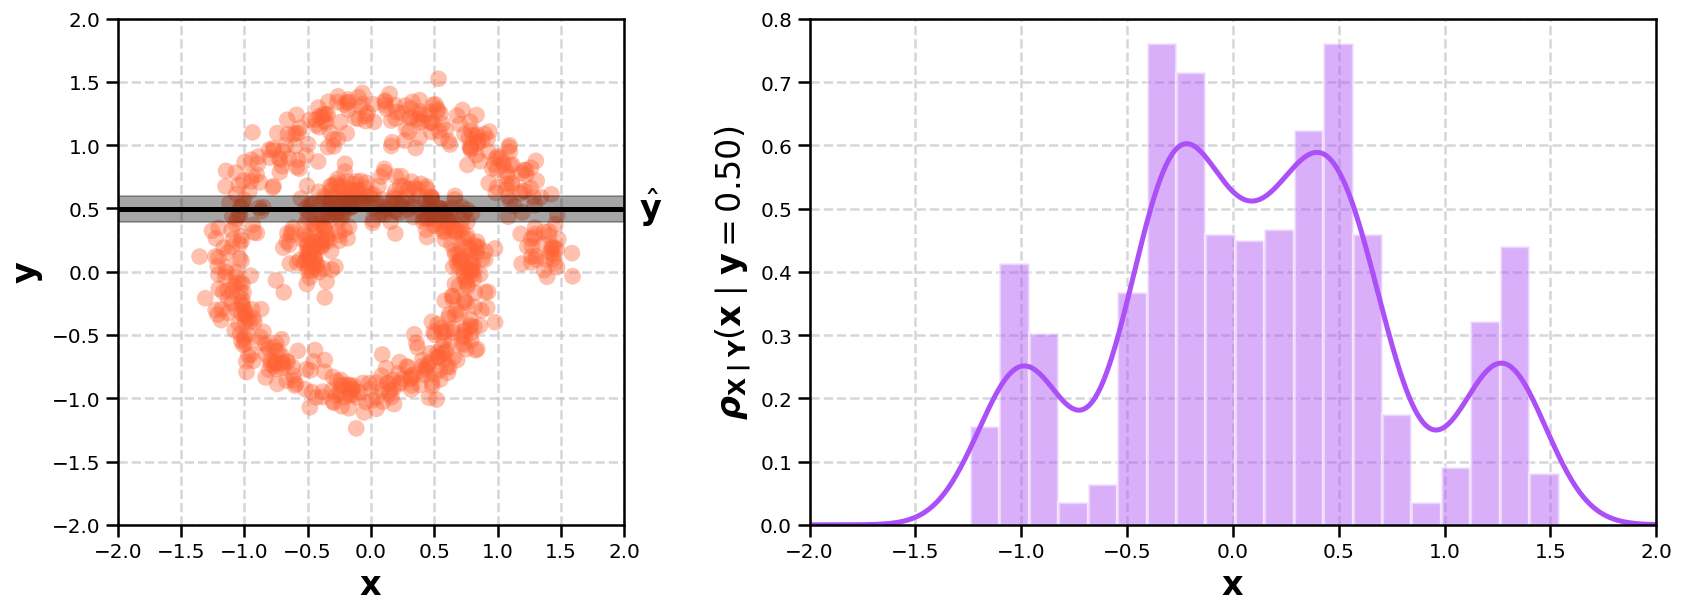

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

from flow import ConditionalFlowMatching

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "axes.labelweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

ORANGE = "#FF6234"
PURPLE = "#AB4FF6"
GRAY = "#BABCC2"

def sample_spiral_joint(num_samples):
    """Generate samples from the spiral joint distribution."""
    rng = np.random.default_rng()

    h = rng.uniform(0.0, 1.0, size=num_samples)
    c3 = rng.normal(0.0, 1.0, size=num_samples)
    c4 = rng.normal(0.0, 1.0, size=num_samples)

    w = 1.5 * np.pi * (1.0 + 2.0 * h)
    x = 0.1 * (w * np.sin(w) + c3)
    y = 0.1 * (w * np.cos(w) + c4)

    return x, y


# Draw train/test data and a conditioning observation
Xs, Ys = sample_spiral_joint(5_000)
print(f"Joint samples from the spiral distribution: {Xs.shape}")

_, y_hat = sample_spiral_joint(1)
print(f"Observation (y_hat) = {y_hat[0]:.3f}")

band = 0.1
x_cond = Xs[np.abs(Ys - y_hat[0]) < band]
print(f"{len(x_cond)} samples lie in the conditioning band")

# -----------------------------------------------------------------------------
# Visualize the joint distribution and the conditional target distribution
# -----------------------------------------------------------------------------
fig, (ax_joint, ax_cond) = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1, 1.3]},
)

# Left: joint samples
ax_joint.scatter(Xs[:800], Ys[:800], color=ORANGE, alpha=0.4, edgecolors="none", s=100)
ax_joint.axhspan(y_hat[0] - band, y_hat[0] + band, color="black", alpha=0.35, zorder=2)
ax_joint.axhline(y_hat[0], color="black", lw=3, zorder=3)
ax_joint.text(
    2.3,
    y_hat[0] - 0.15,
    r"$\hat{\mathbf{y}}$",
    fontsize=20,
    fontweight="bold",
    color="black",
    ha="right",
    va="bottom",
    zorder=4,
)
ax_joint.set(
    xlabel=r"$\mathbf{x}$",
    ylabel=r"$\mathbf{y}$",
    xlim=(-2, 2),
    ylim=(-2, 2),
)
ax_joint.set_box_aspect(1)

# Right: conditional histogram + KDE
x_grid = np.linspace(-2, 2, 600)
kde_cond = gaussian_kde(x_cond)

ax_cond.hist(x_cond, bins=20, density=True, color=PURPLE, alpha=0.45, edgecolor="white", linewidth=2)
ax_cond.plot(x_grid, kde_cond(x_grid), color=PURPLE, lw=3)
ax_cond.set(
    xlabel=r"$\mathbf{x}$",
    ylabel=rf"$\boldsymbol{{\rho}}_{{\mathbf{{X\mid Y}}}}(\mathbf{{x}}\mid\mathbf{{y}}={y_hat[0]:.2f})$",
    xlim=(-2, 2),
)
ax_cond.set_ylim(bottom=0)

for ax in (ax_joint, ax_cond):
    ax.grid(color=GRAY, alpha=0.6, linestyle="--", linewidth=1.5)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)
    ax.tick_params(axis="both", which="major", width=1.5, length=7)
    ax.xaxis.label.set_size(20)
    ax.xaxis.label.set_weight("bold")
    ax.yaxis.label.set_size(20)
    ax.yaxis.label.set_weight("bold")

plt.show()

Iteration (0100/4500) Training Loss = 1.0346 | Testing Loss = 1.1176
Iteration (0200/4500) Training Loss = 1.2028 | Testing Loss = 1.1363
Iteration (0300/4500) Training Loss = 1.0918 | Testing Loss = 1.0634
Iteration (0400/4500) Training Loss = 1.0003 | Testing Loss = 1.0479
Iteration (0500/4500) Training Loss = 0.8484 | Testing Loss = 1.1423
Iteration (0600/4500) Training Loss = 0.9599 | Testing Loss = 0.9141
Iteration (0700/4500) Training Loss = 0.9781 | Testing Loss = 0.9010
Iteration (0800/4500) Training Loss = 0.9074 | Testing Loss = 0.9965
Iteration (0900/4500) Training Loss = 1.0238 | Testing Loss = 0.9983
Iteration (1000/4500) Training Loss = 1.0913 | Testing Loss = 1.0647
Iteration (1100/4500) Training Loss = 1.0051 | Testing Loss = 0.9733
Iteration (1200/4500) Training Loss = 0.9235 | Testing Loss = 1.0565
Iteration (1300/4500) Training Loss = 0.9198 | Testing Loss = 0.7436
Iteration (1400/4500) Training Loss = 1.0154 | Testing Loss = 0.9710
Iteration (1500/4500) Training Los

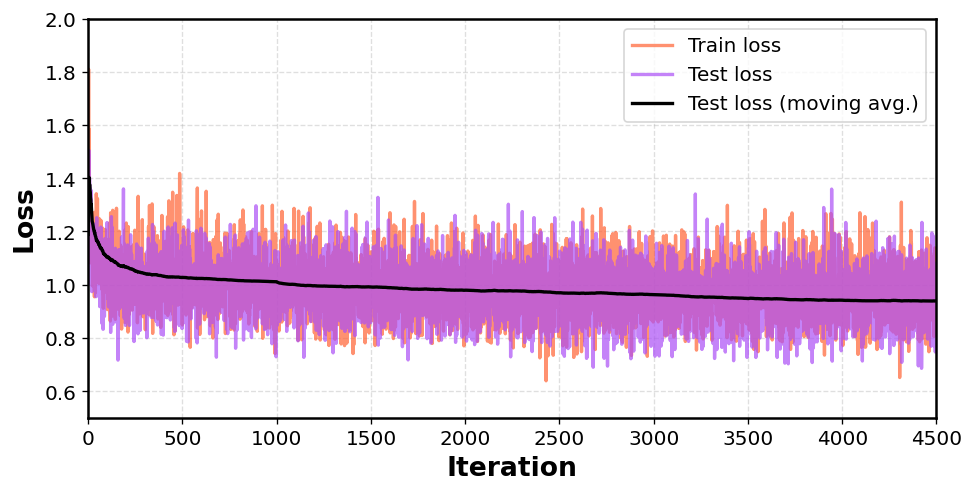

In [2]:
# TRAINING
network = ConditionalFlowMatching(
    n_dim_x=1,
    n_dim_y=1,
    width=256,
    depth=4,
    activation="ReLU",
)

X_train, Y_train = sample_spiral_joint(10_000)
X_test, Y_test = sample_spiral_joint(1_000)

train_losses, test_losses, ma_test_losses = network.train(
    X_train=torch.from_numpy(X_train).float(),
    Y_train=torch.from_numpy(Y_train).float(),
    X_test=torch.from_numpy(X_test).float(),
    Y_test=torch.from_numpy(Y_test).float(),
    n_iters=4500,
    batch_size=256,
)

# -----------------------------------------------------------------------------
# Loss curves
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)

ax.plot(range(len(train_losses)), train_losses, color=ORANGE, linewidth=2, alpha=0.7, label="Train loss")
ax.plot(range(len(test_losses)), test_losses, color=PURPLE, linewidth=2, alpha=0.7, label="Test loss")
ax.plot(range(len(ma_test_losses)), ma_test_losses, color="black", linewidth=2, label="Test loss (moving avg.)")

ax.set_xlabel("Iteration", fontsize=16, fontweight="bold")
ax.set_ylabel("Loss", fontsize=16, fontweight="bold")
ax.set_xlim(0, len(train_losses))
ax.set_ylim(0.5, 2)
ax.grid(alpha=0.4, linestyle="--")
ax.legend(frameon=True, fontsize=12)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color("black")

plt.show()

Sampling used 13 steps


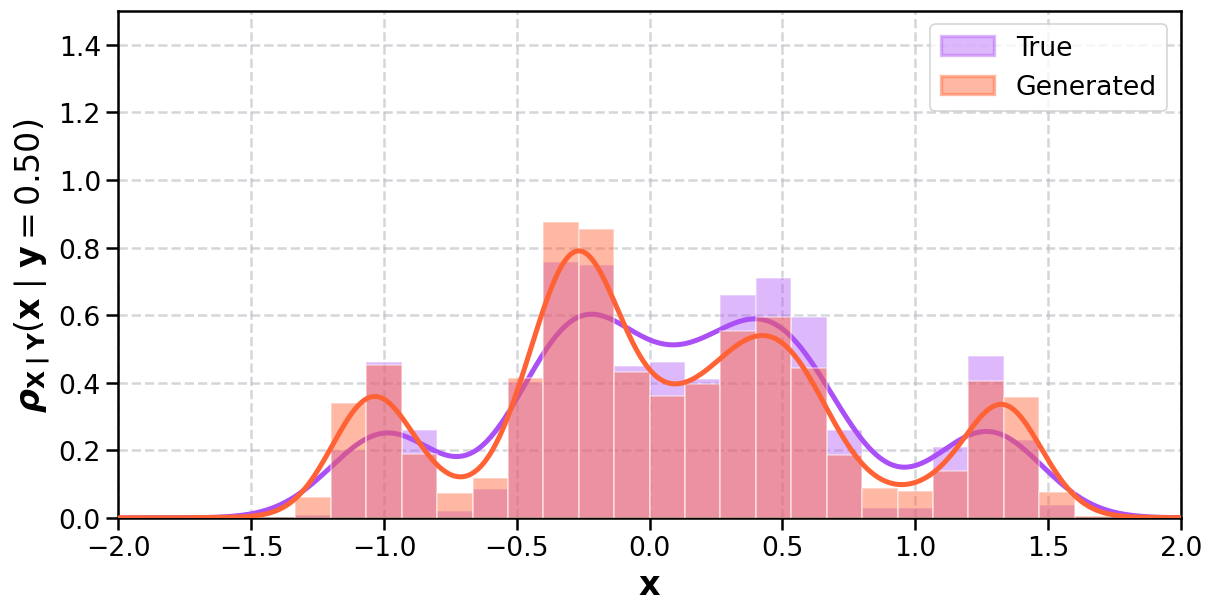

In [3]:
# SAMPLING
samples, n_steps_used = network.sample(
    y_cond=torch.from_numpy(y_hat).float(),
    batch_size=10_000,
    ema=True,
    return_path=False,
)
print(f"Sampling used {n_steps_used} steps")

# -----------------------------------------------------------------------------
# Compare the empirical conditional distribution with generated samples
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

bin_edges = np.linspace(-2, 2, 31)
x_grid = np.linspace(-2, 2, 600)

kde_true = gaussian_kde(x_cond.reshape(-1))
kde_generated = gaussian_kde(samples.reshape(-1))

ax.hist(
    x_cond,
    bins=bin_edges,
    density=True,
    color=PURPLE,
    alpha=0.40,
    edgecolor="white",
    linewidth=1.0,
    label="True",
    zorder=1,
)
ax.plot(x_grid, kde_true(x_grid), color=PURPLE, linewidth=3, zorder=2)

ax.hist(
    samples,
    bins=bin_edges,
    density=True,
    color=ORANGE,
    alpha=0.45,
    edgecolor="white",
    linewidth=1.0,
    label="Generated",
    zorder=3,
)
ax.plot(x_grid, kde_generated(x_grid), color=ORANGE, linewidth=3, zorder=4)

ax.set(
    xlabel=r"$\mathbf{x}$",
    ylabel=rf"$\boldsymbol{{\rho}}_{{\mathbf{{X\mid Y}}}}(\mathbf{{x}}\mid\mathbf{{y}}={y_hat[0]:.2f})$",
    xlim=(-2, 2),
    ylim=(0, 1.5),
)
ax.grid(color=GRAY, alpha=0.6, linestyle="--", linewidth=1.5)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.5)

ax.tick_params(axis="both", which="major", labelsize=16, width=1.5, length=7)
ax.xaxis.label.set_size(20)
ax.xaxis.label.set_weight("bold")
ax.yaxis.label.set_size(20)
ax.yaxis.label.set_weight("bold")

legend = ax.legend(fontsize=16)
for handle, color in zip(legend.legend_handles, [PURPLE, ORANGE]):
    handle.set_edgecolor(color)
    handle.set_linewidth(2)

plt.show()